# 🏋️ PROYECTO SPRINT 14: MODEL FITNESS
## Predicción y retención de clientes

### Introducción

En este proyecto analizaremos los datos de clientes de la cadena de gimnasios **Model Fitness**, con el objetivo de comprender los factores relacionados con la **cancelación de membresías (churn)** y desarrollar una estrategia que ayude a mejorar la retención de clientes.

A partir de información sobre las características de los usuarios, sus contratos, frecuencia de visitas, participación en actividades grupales y gastos adicionales, realizaremos un análisis exploratorio de datos (EDA) para identificar patrones entre los clientes que permanecen y aquellos que abandonan el gimnasio.

Posteriormente, construiremos modelos de **clasificación** para predecir la probabilidad de cancelación y compararemos su desempeño mediante diferentes métricas. También utilizaremos técnicas de clustering para identificar grupos de clientes con características similares y analizar cuáles presentan un mayor riesgo de abandono.

Finalmente, interpretaremos los resultados para identificar los grupos objetivo, los factores que más influyen en la cancelación y proponer **recomendaciones concretas de retención y atención al cliente**.

## 1. Análisis exploratorio de datos (EDA)

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# carga los datos
gym = pd.read_csv('gym_churn_us.csv')

# muestra las primeras filas
print(gym.head())

# información general del dataset
print(gym.info())

# estadísticas descriptivas
print(gym.describe())

   gender  Near_Location  Partner  Promo_friends  Phone  Contract_period  \
0       1              1        1              1      0                6   
1       0              1        0              0      1               12   
2       0              1        1              0      1                1   
3       0              1        1              1      1               12   
4       1              1        1              1      1                1   

   Group_visits  Age  Avg_additional_charges_total  Month_to_end_contract  \
0             1   29                     14.227470                    5.0   
1             1   31                    113.202938                   12.0   
2             0   28                    129.448479                    1.0   
3             1   33                     62.669863                   12.0   
4             0   26                    198.362265                    1.0   

   Lifetime  Avg_class_frequency_total  Avg_class_frequency_current_month  \
0  

### Comparación de las características según la cancelación

A continuación, se calculan los valores medios de las características para los clientes que cancelaron su membresía y para aquellos que permanecieron. Esto permite identificar diferencias entre ambos grupos y detectar posibles factores relacionados con la cancelación.

In [ ]:
# Valores medios de las características según la cancelación
gym.groupby('Churn').mean()

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month
Churn,,,,,,,,,,,,,
0,0.510037,0.873086,0.534195,0.353522,0.903709,5.747193,0.464103,29.976523,158.445715,5.283089,4.711807,2.024876,2.027882
1,0.510839,0.768143,0.355325,0.183789,0.902922,1.728558,0.268615,26.989632,115.082899,1.662582,0.990575,1.474995,1.044546


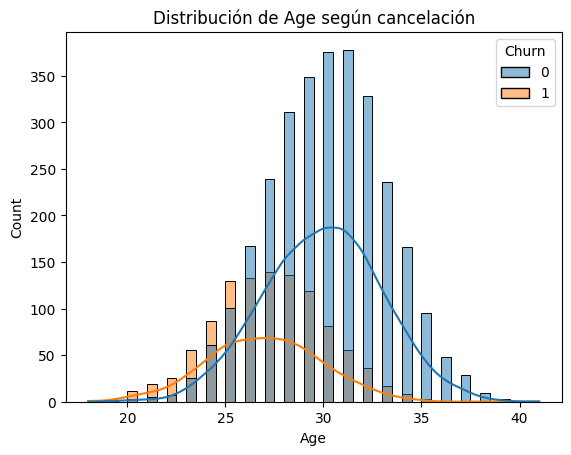

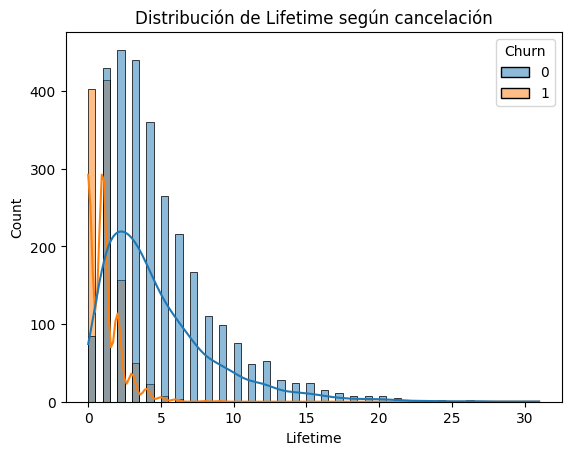

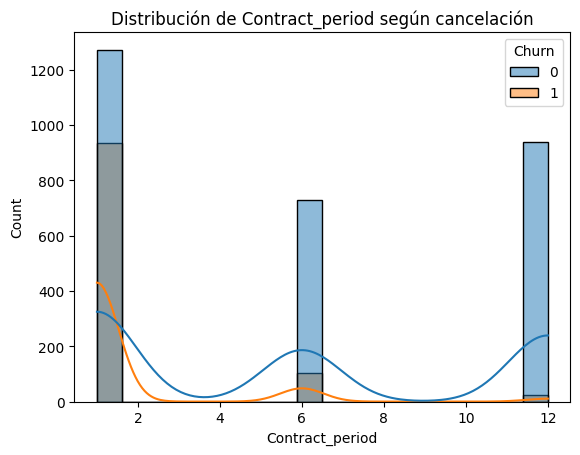

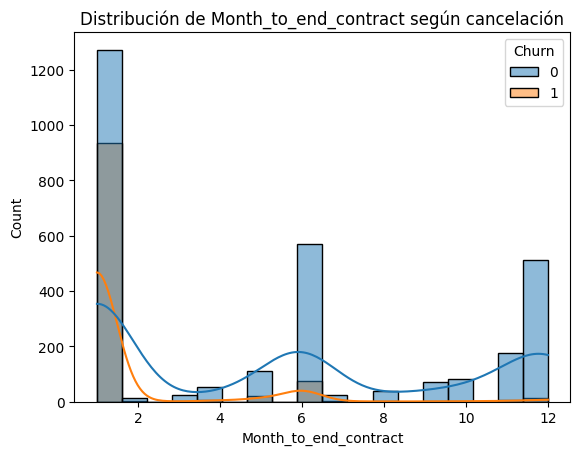

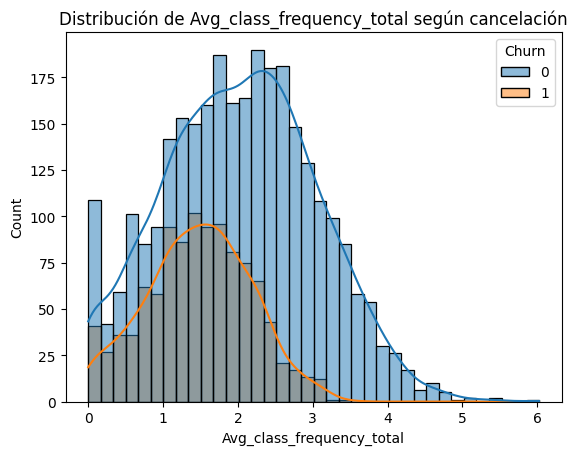

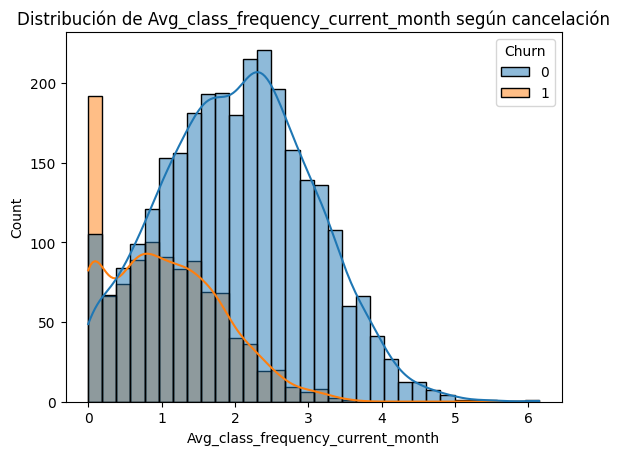

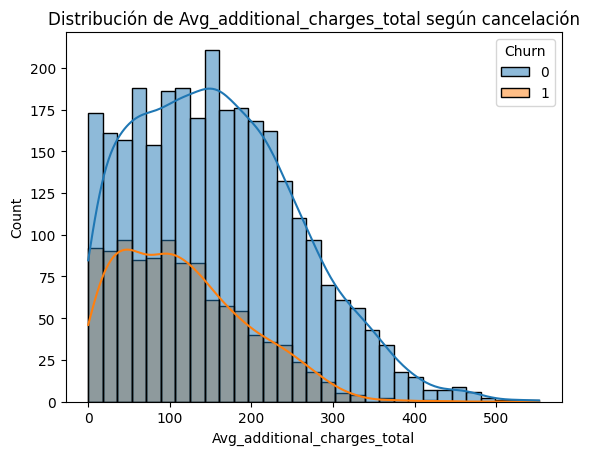

In [ ]:
# Distribución de las características según la cancelación

features = [
    'Age',
    'Lifetime',
    'Contract_period',
    'Month_to_end_contract',
    'Avg_class_frequency_total',
    'Avg_class_frequency_current_month',
    'Avg_additional_charges_total'
]

for feature in features:
    sns.histplot(data=gym, x=feature, hue='Churn', kde=True)
    plt.title(f'Distribución de {feature} según cancelación')
    plt.show()

## Comparación de los grupos ##

Al comparar las características de los usuarios que permanecieron y los que cancelaron, se observan diferencias importantes en varias variables. Los usuarios que cancelaron presentan, en promedio, menor antigüedad, contratos más cortos, menor frecuencia de asistencia a clases y menor gasto en servicios adicionales. También son más jóvenes y presentan valores inferiores en variables relacionadas con la participación en actividades grupales, promociones y afiliación con empresas asociadas.

Por otro lado, las variables gender y Phone presentan valores promedio muy similares entre ambos grupos, por lo que no se observan diferencias relevantes entre quienes permanecieron y quienes cancelaron.

## Conclusiones de las distribuciones

Las distribuciones muestran diferencias claras entre los usuarios que permanecieron y los que cancelaron. Los usuarios que cancelaron tienden a ser más jóvenes y presentan una menor antigüedad (Lifetime). También se observa una mayor concentración de cancelaciones entre los usuarios con contratos cortos, especialmente de un mes.

En cuanto a la actividad, los usuarios que cancelaron presentan una menor frecuencia promedio de visitas tanto histórica como durante el mes actual. También muestran menores cargos adicionales promedio.

Las variables relacionadas con la duración del contrato y la antigüedad muestran diferencias particularmente marcadas entre ambos grupos. En general, los usuarios con menor antigüedad, contratos más cortos y menor frecuencia de asistencia parecen presentar una mayor tendencia a cancelar.

In [ ]:
# Matriz de correlación
corr_matrix = gym.corr()

corr_matrix

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
gender,1.000000,0.006699,-0.010463,-0.005033,-0.008542,0.000502,0.017879,0.013807,-0.009334,-0.001281,0.013579,0.014620,0.009156,0.000708
Near_Location,0.006699,1.000000,-0.005119,0.210964,-0.015763,0.150233,0.154728,0.058358,0.040761,0.143961,0.070921,0.043127,0.062664,-0.128098
Partner,-0.010463,-0.005119,1.000000,0.451960,0.009970,0.306166,0.022710,0.047480,0.022941,0.294632,0.061229,0.024938,0.045561,-0.157986
Promo_friends,-0.005033,0.210964,0.451960,1.000000,0.001982,0.244552,0.120170,0.050113,0.036898,0.239553,0.072721,0.028063,0.053768,-0.162233
Phone,-0.008542,-0.015763,0.009970,0.001982,1.000000,-0.006893,-0.010099,-0.011403,0.009279,-0.011196,-0.018801,0.008340,0.013375,-0.001177
Contract_period,0.000502,0.150233,0.306166,0.244552,-0.006893,1.000000,0.169991,0.138249,0.111445,0.973064,0.170725,0.096211,0.159407,-0.389984
Group_visits,0.017879,0.154728,0.022710,0.120170,-0.010099,0.169991,1.000000,0.080934,0.032079,0.163703,0.075853,0.056695,0.075923,-0.175325
Age,0.013807,0.058358,0.047480,0.050113,-0.011403,0.138249,0.080934,1.000000,0.080240,0.134511,0.164693,0.119953,0.183095,-0.404735
Avg_additional_charges_total,-0.009334,0.040761,0.022941,0.036898,0.009279,0.111445,0.032079,0.080240,1.000000,0.113958,0.079028,0.044426,0.079570,-0.198697
Month_to_end_contract,-0.001281,0.143961,0.294632,0.239553,-0.011196,0.973064,0.163703,0.134511,0.113958,1.000000,0.161078,0.085387,0.147605,-0.381393


## Modelos para predecir la cancelación de usuarios

In [ ]:
# Importamos pandas para trabajar con el dataset
import pandas as pd

# Cargamos el dataset de clientes del gimnasio
df = pd.read_csv('/datasets/gym_churn_us.csv')

# Comprobamos que el dataset se haya cargado correctamente
print('Tamaño del dataset:', df.shape)

# Mostramos las primeras filas del dataset
df.head()

Tamaño del dataset: (4000, 14)


,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.227470,5.0,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12.0,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1.0,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12.0,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1.0,3,1.113884,1.120078,0


In [ ]:
# Importamos la función para dividir los datos en conjuntos de entrenamiento y validación
from sklearn.model_selection import train_test_split

# Separamos las características predictoras de la variable objetivo
# X contiene todas las variables que utilizaremos para predecir la cancelación
X = df.drop('Churn', axis=1)

# y contiene la variable objetivo:
# 1 = el cliente canceló
# 0 = el cliente permaneció
y = df['Churn']

# Dividimos los datos en dos conjuntos:
# 80% de los datos serán utilizados para entrenar los modelos
# 20% serán utilizados para validar los modelos
# random_state=42 garantiza que la división sea reproducible
# stratify=y conserva una proporción similar de las clases 0 y 1
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Comprobamos el tamaño de ambos conjuntos
print('Tamaño del conjunto de entrenamiento:', X_train.shape)
print('Tamaño del conjunto de validación:', X_valid.shape)

Tamaño del conjunto de entrenamiento: (3200, 13)
Tamaño del conjunto de validación: (800, 13)


## Regresión logística

In [ ]:
# Importamos el modelo de regresión logística
from sklearn.linear_model import LogisticRegression

# Creamos el modelo de regresión logística
# random_state=42 permite obtener resultados reproducibles
logistic_model = LogisticRegression(random_state=42, max_iter=1000)

# Entrenamos el modelo utilizando únicamente los datos de entrenamiento
logistic_model.fit(X_train, y_train)

# Realizamos predicciones sobre el conjunto de validación
logistic_predictions = logistic_model.predict(X_valid)

# Mostramos algunas de las predicciones realizadas
print(logistic_predictions[:10])

[0 0 1 0 0 0 0 0 0 0]


## Bosque aleatorio

In [ ]:
# Importamos el modelo de bosque aleatorio
from sklearn.ensemble import RandomForestClassifier

# Creamos el modelo de bosque aleatorio
# random_state=42 permite obtener resultados reproducibles
random_forest_model = RandomForestClassifier(
    random_state=42
)

# Entrenamos el modelo utilizando los datos de entrenamiento
random_forest_model.fit(X_train, y_train)

# Realizamos predicciones sobre el conjunto de validación
random_forest_predictions = random_forest_model.predict(X_valid)

# Mostramos algunas de las predicciones realizadas
print(random_forest_predictions[:10])

[0 0 1 0 0 0 0 0 0 0]


In [ ]:
# Importamos las funciones que utilizaremos para evaluar los modelos
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Calculamos las métricas para el modelo de regresión logística
logistic_accuracy = accuracy_score(y_valid, logistic_predictions)
logistic_precision = precision_score(y_valid, logistic_predictions)
logistic_recall = recall_score(y_valid, logistic_predictions)

# Calculamos las métricas para el modelo de bosque aleatorio
random_forest_accuracy = accuracy_score(y_valid, random_forest_predictions)
random_forest_precision = precision_score(y_valid, random_forest_predictions)
random_forest_recall = recall_score(y_valid, random_forest_predictions)

# Mostramos los resultados de la regresión logística
print('Regresión logística:')
print('Exactitud:', logistic_accuracy)
print('Precisión:', logistic_precision)
print('Recall:', logistic_recall)

# Mostramos los resultados del bosque aleatorio
print('\nBosque aleatorio:')
print('Exactitud:', random_forest_accuracy)
print('Precisión:', random_forest_precision)
print('Recall:', random_forest_recall)

Regresión logística:
Exactitud: 0.92375
Precisión: 0.8756218905472637
Recall: 0.8301886792452831

Bosque aleatorio:
Exactitud: 0.9275
Precisión: 0.885
Recall: 0.8349056603773585


## Conclusiones

El modelo de bosque aleatorio obtuvo mejores resultados que la regresión logística en las tres métricas evaluadas. Su exactitud fue de 0.9275, su precisión de 0.8850 y su recall de 0.8349. Por lo tanto, el bosque aleatorio presenta un mejor desempeño para predecir la cancelación de usuarios en este conjunto de datos.

## Crear clústeres de usuarios/as

In [4]:
# Importamos StandardScaler para estandarizar las características
from sklearn.preprocessing import StandardScaler

# Separamos las características de la variable objetivo Churn
# No utilizaremos Churn para formar los clústeres
X_cluster = gym.drop('Churn', axis=1)

# Creamos el objeto para estandarizar los datos
scaler = StandardScaler()

# Estandarizamos las características
X_cluster_scaled = scaler.fit_transform(X_cluster)

# Mostramos las primeras filas de los datos estandarizados
print(X_cluster_scaled[:5])

[[ 0.97970588  0.42788074  1.02686062  1.49716101 -3.05985201  0.28989014
   1.19403206 -0.0565538  -1.37753121  0.16160501 -0.19332863 -1.91191971
  -1.67847198]
 [-1.0207145   0.42788074 -0.973842   -0.66793083  0.32681319  1.60882159
   1.19403206  0.55732732 -0.35021325  1.83194105  0.87368001  0.04517569
   0.1360137 ]
 [-1.0207145   0.42788074  1.02686062 -0.66793083  0.32681319 -0.8092194
  -0.83749845 -0.36349436 -0.1815923  -0.79287273 -0.46008079 -0.02049263
  -0.02901851]
 [-1.0207145   0.42788074  1.02686062  1.49716101  0.32681319  1.60882159
   1.19403206  1.17120844 -0.87472237  1.83194105 -0.46008079  1.36465509
   1.51045005]
 [ 0.97970588  0.42788074  1.02686062  1.49716101  0.32681319 -0.8092194
  -0.83749845 -0.97737548  0.5336998  -0.79287273 -0.19332863 -0.78707638
  -0.61454183]]


In [ ]:
%pip install scikit-learn

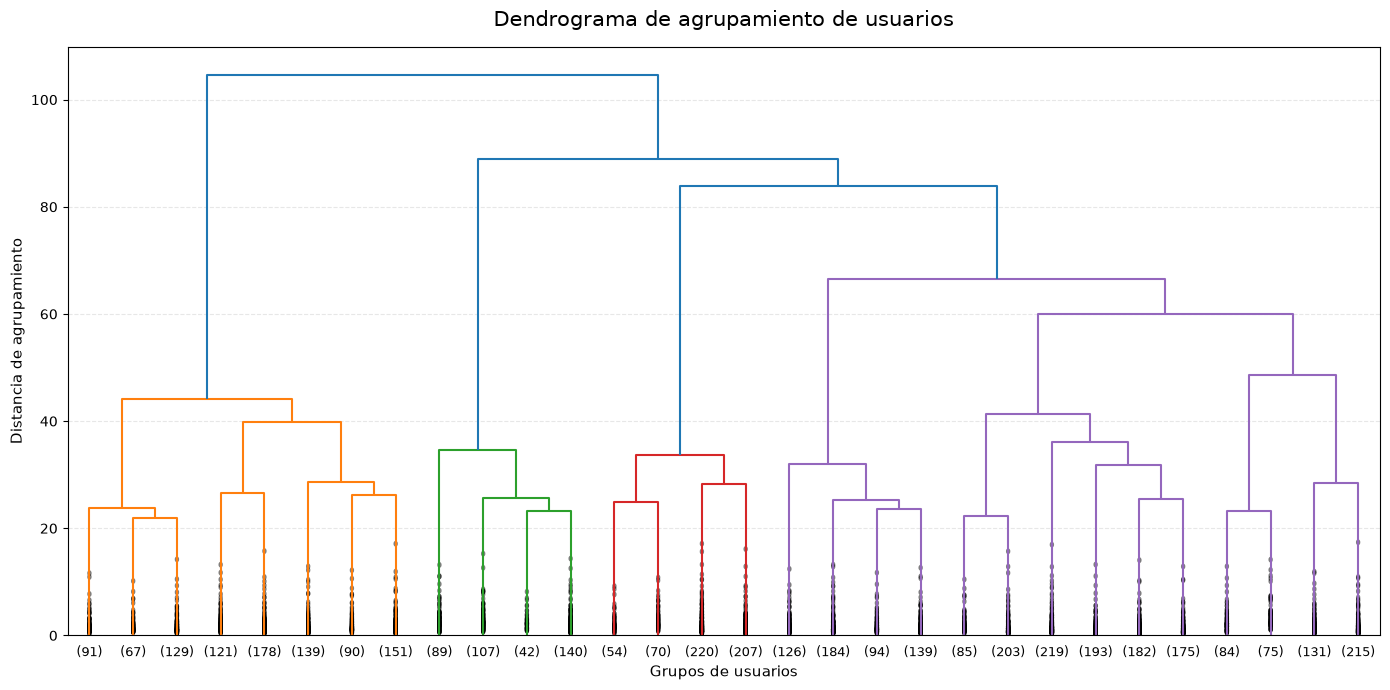

In [5]:

# Importamos las funciones necesarias
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Calculamos la matriz de distancias
linked = linkage(X_cluster_scaled, method='ward')

# Creamos una visualización resumida del dendrograma
plt.figure(figsize=(14, 7))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True,
    show_contracted=True,
    leaf_rotation=0,
    leaf_font_size=9
)

# Personalizamos el gráfico
plt.title('Dendrograma de agrupamiento de usuarios', fontsize=15, pad=15)
plt.xlabel('Grupos de usuarios', fontsize=11)
plt.ylabel('Distancia de agrupamiento', fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()

plt.show()

### Interpretación del dendrograma

El dendrograma permite visualizar la similitud entre los usuarios y comprender cómo se agrupan según sus características de comportamiento.

La distancia entre las ramas representa el grado de diferencia entre las observaciones. A partir de esta estructura se identifican agrupaciones de usuarios que posteriormente permiten analizar distintos perfiles y patrones de comportamiento.

Esta segmentación sirve como base para diseñar estrategias diferenciadas de fidelización y retención de clientes.

In [7]:
# Importamos KMeans para crear los clústeres de usuarios
from sklearn.cluster import KMeans

# Creamos el modelo K-means con 5 clústeres
# random_state=42 permite que los resultados sean reproducibles
kmeans = KMeans(n_clusters=5, random_state=42)

# Entrenamos el modelo utilizando los datos estandarizados
kmeans.fit(X_cluster_scaled)

# Asignamos a cada usuario el número del clúster al que pertenece
gym['cluster'] = kmeans.labels_

# Mostramos los primeros usuarios con su clúster asignado
print(gym[['cluster']].head())

   cluster
0        1
1        3
2        0
3        2
4        1


In [8]:
# Calculamos el valor medio de cada característica para cada clúster
cluster_means = gym.groupby('cluster').mean()

# Mostramos los valores medios de las características de cada clúster
print(cluster_means)

           gender  Near_Location   Partner  Promo_friends     Phone  \
cluster                                                               
0        0.484801       0.698363  0.301637       0.007015  0.899454   
1        0.494471       0.947867  0.791469       0.998420  0.906793   
2        0.464396       0.913313  0.766254       0.493808  0.925697   
3        0.547794       0.937500  0.742647       0.424632  0.863971   
4        0.568233       0.878076  0.178971       0.048098  0.914989   

         Contract_period  Group_visits        Age  \
cluster                                             
0               1.733437      0.255651  28.074825   
1               2.740916      0.431280  28.903633   
2              10.495356      0.506192  30.091331   
3              11.194853      0.575368  29.720588   
4               2.120805      0.456376  29.993289   

         Avg_additional_charges_total  Month_to_end_contract  Lifetime  \
cluster                                                 

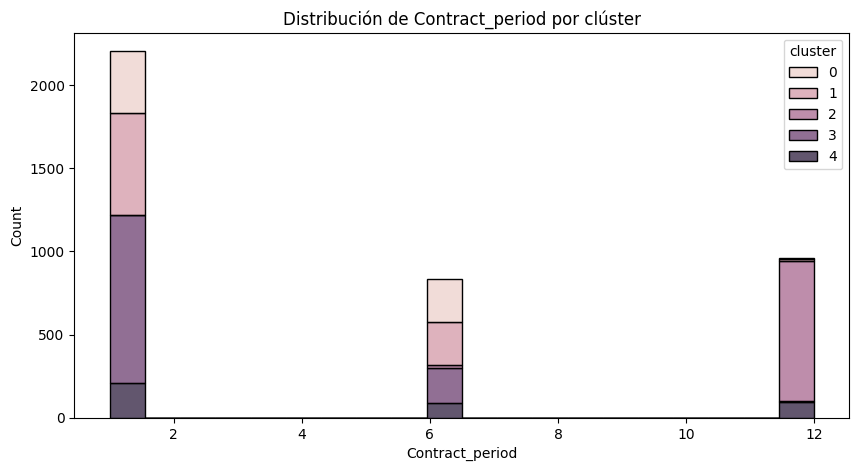

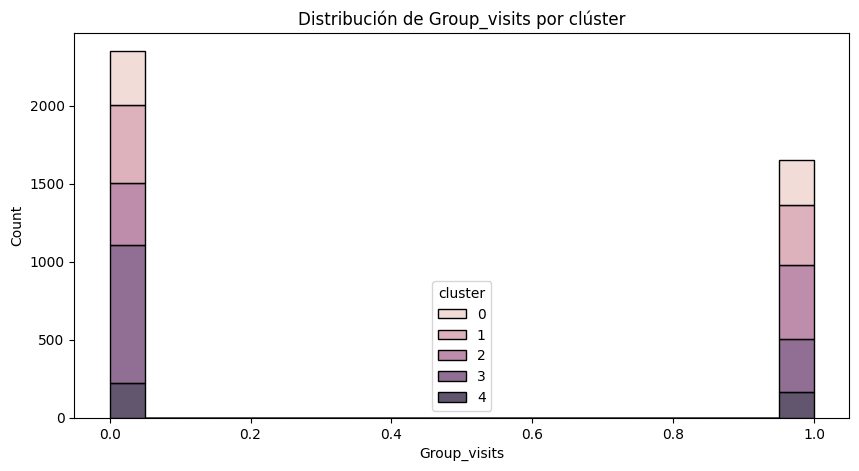

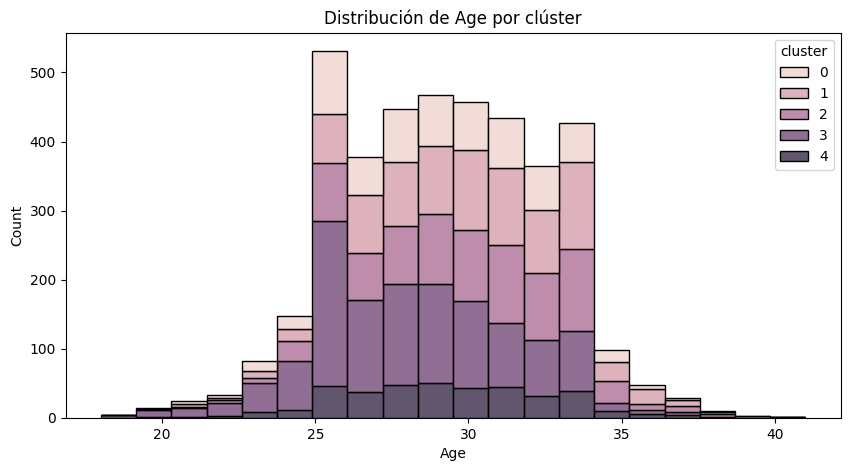

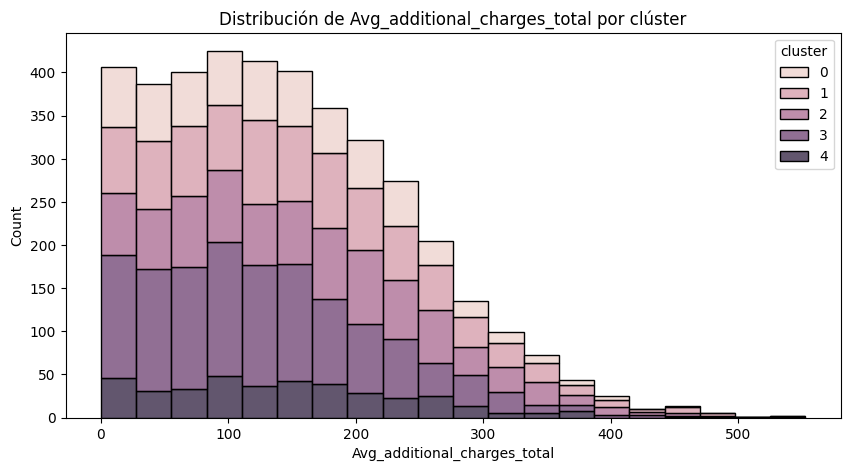

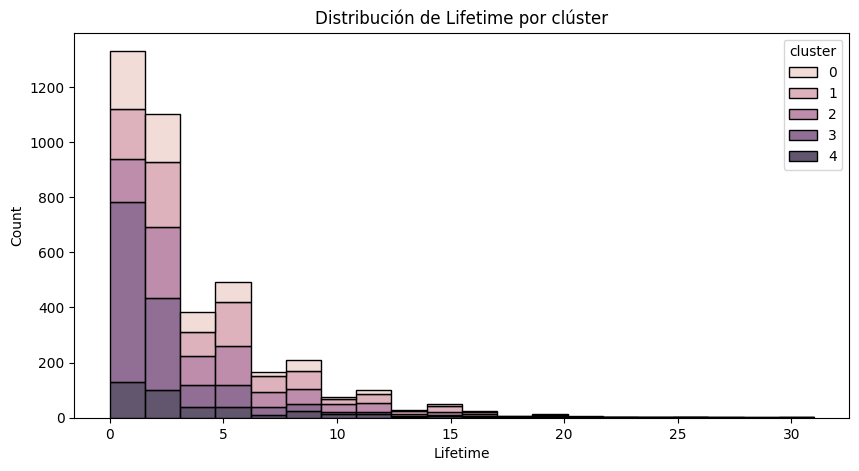

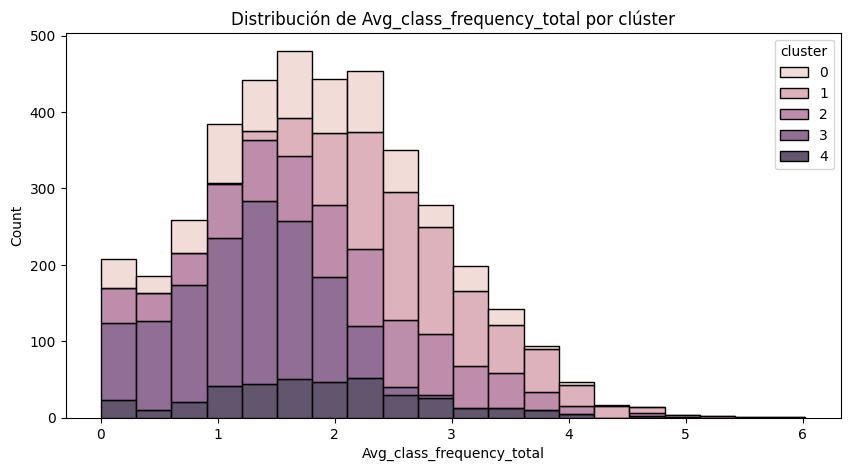

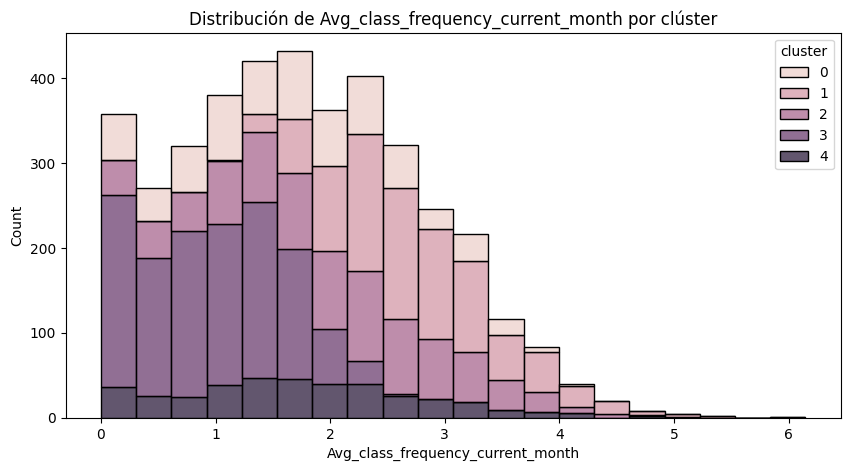

In [ ]:
# Importamos seaborn para crear las gráficas de distribución
import seaborn as sns

# Importamos matplotlib para mostrar y configurar las gráficas
import matplotlib.pyplot as plt

# Seleccionamos algunas características importantes para comparar los clústeres
features = [
    'Contract_period',
    'Group_visits',
    'Age',
    'Avg_additional_charges_total',
    'Lifetime',
    'Avg_class_frequency_total',
    'Avg_class_frequency_current_month'
]

# Creamos una gráfica de distribución para cada característica
for feature in features:

    # Creamos una nueva figura para cada característica
    plt.figure(figsize=(10, 5))

    # Mostramos la distribución de la característica separada por clúster
    sns.histplot(
        data=df,
        x=feature,
        hue='cluster',
        multiple='stack',
        bins=20
    )

    # Agregamos el título de la gráfica
    plt.title(f'Distribución de {feature} por clúster')

    # Mostramos la gráfica
    plt.show()

## Conclusiones y recomendaciones

El análisis de los clústeres permitió identificar diferencias importantes en el comportamiento y la retención de los clientes.

1. Priorizar la atención al clúster 3, que presenta el mayor riesgo de cancelación.
Este grupo tiene una tasa de cancelación de aproximadamente 57.3%, muy superior al resto. Se recomienda implementar acciones de retención dirigidas a estos clientes, como promociones personalizadas, seguimiento frecuente y ofertas para incentivar su asistencia.

2. Reforzar la fidelización de los clientes de los clústeres 2 y 1.
Son los grupos con menor tasa de cancelación (2.2% y 9.0%, respectivamente). Se pueden implementar programas de lealtad, beneficios por permanencia y promociones especiales para mantener su compromiso con el gimnasio.

3. Incentivar la frecuencia de asistencia.
Los clientes con mayor frecuencia de clases muestran características asociadas con una mejor retención. Se recomienda enviar recordatorios, crear retos de asistencia y ofrecer incentivos por alcanzar determinados objetivos de entrenamiento.

4. Promover contratos de mayor duración.
El clúster 2 presenta un período de contrato promedio considerablemente mayor (11.85 meses) y también la menor tasa de cancelación. Por ello, puede ser conveniente promover planes de mayor duración mediante descuentos, beneficios adicionales o promociones de renovación anticipada.

Ejemplos de acciones de marketing:
Identificar a los clientes del clúster 3 y enviarles ofertas personalizadas para incentivar su permanencia.
Crear un programa de recompensas por asistencia.
Ofrecer beneficios y descuentos por contratos de 6 o 12 meses.
Mantener campañas de fidelización para los clientes de los clústeres 1 y 2.